# IMPORT LIBRARY

In [1]:
import os
import random
import datetime
import json
import pandas   as pd
import numpy    as np

from tqdm                       import tqdm
from preProcessingDataTEP       import PreProcessData
from utility.matpilotDraw       import MatPlot

with open('utility/modelConfig.json', 'r') as configFile:
    config = json.load(configFile)
myConfig   = config["tep"]

# LOADING DATA

In [2]:
# This function is used to load and save data into H5 file
# preData     = PreProcessData(config=myConfig)
# outputDir   = os.path.expanduser(preData.config["dataDir"])    
# oriData     = preData.loadCSVDataFile(dir               = outputDir, 
#                                       removeHigherThr   = True, 
#                                       columnNames       = ["Stripper Level","Stripper Level","Stripper Level"],
#                                       thr               = ["down", "down", "up"]) 




# preData.save2H5Format(dir = outputDir, data = oriData)

In [3]:
plot               = MatPlot() 

# ----------------------    
# Reactor, Separator,Stripper
# ----------------------
np.random.seed(1)
random.seed(1)

preData     = PreProcessData(config=myConfig)
outputDir   = os.path.expanduser(preData.config["dataDir"])
rawData             = preData.loadDataFromH5Format(dir = outputDir, name="data/teps.h5", case="all", reduceSampleRate = False)
# withRULData         = preData.addRULAndEnvironment(rawData)
# withoutInitRawData  = preData.removeInitState(inData= withRULData)


# for idxCase,vlData in rawData.items():
#     print("----------------------------------")
#     print(f'The case {idxCase}: {vlData.shape}')
#     print(vlData)

print(rawData[1])


Process:10137||2025-02-12 06:55:17,270-INFO [preProcessingDataTEP.py:loadDataFromH5Format():298]:Loading data from H5 files ...
Process:10137||2025-02-12 06:55:18,639-INFO [preProcessingDataTEP.py:loadDataFromH5Format():325]:Finish loading data from H5 files at case all...


         Id    Time      D feed     E Feed     A Feed  A and C Feed  \
0         1    0.00   99.997400   9.377656  21.520930     57.604400   
1         1    0.05  100.000000   9.385454  21.481414     57.602812   
2         1    0.10  100.000000   9.412770  21.458201     57.620730   
3         1    0.15  100.000000   9.432830  21.427658     57.610192   
4         1    0.20   99.998592   9.437429  21.407315     57.592689   
...     ...     ...         ...        ...        ...           ...   
284023  100  144.95  100.000000  10.314342  24.384190     58.342068   
284024  100  145.00  100.000000  10.336074  24.304572     58.414732   
284025  100  145.05  100.000000  10.364081  24.077780     58.454643   
284026  100  145.10  100.000000  10.399730  23.910715     58.425980   
284027  100  145.15  100.000000  10.425891  24.430138     58.154818   

          Recycle      Purge  Separator   Stripper  ...  Component G to Purge  \
0       68.366473  10.426470  32.729951  44.270765  ...           

In [4]:
preData.showScenario()

scenario 1: mode 6: reactor     -> separator
scenario 2: mode 4: reactor     -> stripper
scenario 3: mode 6: separator   -> stripper
scenario 4: mode 2: reactor     -> separator    -> stripper
scenario 5: mode 1: reactor     -> stripper     -> separator
scenario 6: mode 5: separator   -> stripper     -> separator
scenario 7: mode 2: reactor     -> separator


In [5]:
# Draw the data
# curTraj=ectory = preData.getTrajectoryAt(inData= withoutInitRawData, case = 2, idxTrajectory= 1)
# for feature in preData.allHeadline:
#     plot.draw2D(curTrajectory["Time"],curTrajectory[feature],titlefeature)

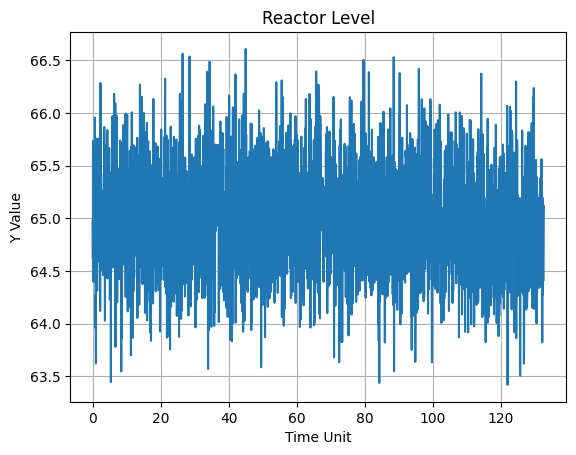

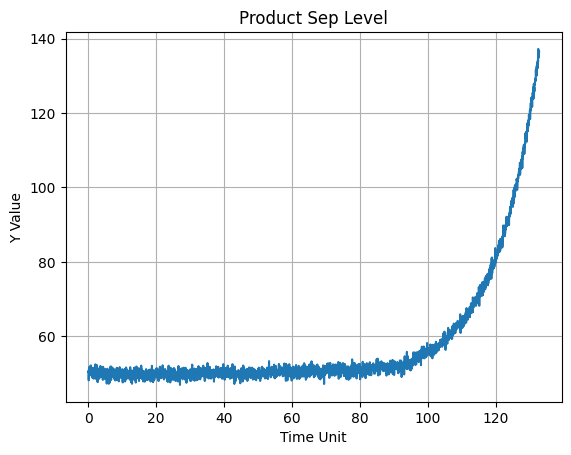

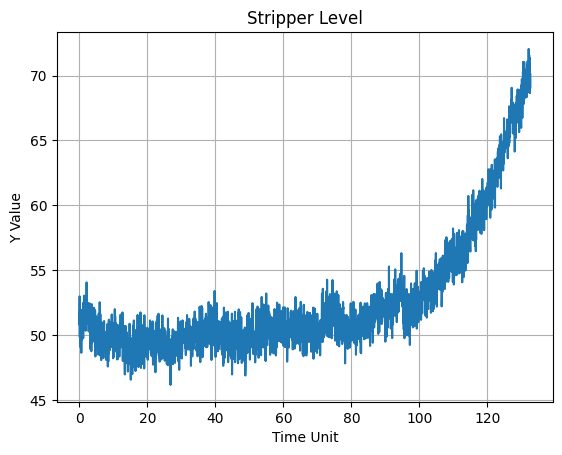

In [12]:
for idx in range(1):
    curTrajectory = preData.getTrajectoryAt(inData= rawData, case = 6, idxTrajectory= idx + 1)
    for idxHeadline in ['Reactor Level', 'Product Sep Level', 'Stripper Level']: 
        plot.draw2D(curTrajectory["Time"],curTrajectory[idxHeadline], title=idxHeadline)


In [7]:
cleanData           = preData.cleanData(rawSignal               =   withoutInitRawData,
                                            columnName          =   preData.allWithoutLabel,
                                            getMovingAverage    =   True,
                                            flipToDown          =   True)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   True)

movedData           = preData.movingToPeak(cleanData)


NameError: name 'withoutInitRawData' is not defined

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData= cleanData, case = 2, idxTrajectory= 1)
for feature in preData.allHeadline:
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
# Draw the data
print(cleanData)

### d. Normalize the data

In [ ]:
norData             = preData.normalizeDataAllModes(movedData)                # Normalize the data
# print(norData)

In [ ]:
# Draw the data
curTrajectory = preData.getTrajectoryAt(inData = norData, case = 2, idxTrajectory = 1)
for feature in preData.allHeadline:
    print(feature)
    plot.draw2D(curTrajectory["Time"],curTrajectory[feature],title=feature)

In [ ]:
plot = MatPlot()

plot.subPlotMultiImg(inY = hi["reactor"],  numRow=20, numCol=5)

### g. Split into each sequence

In [ ]:

seqTrainXY   = preData.getTensorData(norData, component =   "reactor", case = 1 )
# seqValXY   = preData.splitAllDataIntoSequences(valXY)  

# print(seqTrainXY[0].shape,seqTrainXY[1].shape)
# print(seqTrainXY[0][2011][:,0])

### h. Visualize the tensor data

In [ ]:

# Creating an array from 1 to 3000
#time = np.arange(1, 10)
# t= 0:200
# plot.draw1D(yCoor=seqTrainXY[1][0:t])
plot.draw1D(yCoor=seqTrainXY[0][2011][:,3])
            


# 4. Model and training

### To tensor

In [ ]:
tensorTrainXY       = data.TensorDataset(seqTrainXY[0],seqTrainXY[1])
tensorValXY         = data.TensorDataset(seqValXY[0],seqValXY[1])

In [ ]:
train_loader = data.DataLoader(tensorTrainXY,
                                batch_size  =   config.batch_size,
                                shuffle     =   False, 
                                num_workers =   config.num_workers)
        
val_loader = data.DataLoader(  tensorValXY, 
                                batch_size  =   config.val_batch_size, 
                                shuffle     =   False, 
                                num_workers =   config.num_workers)